### B1: Puzzle

In [231]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

### Canny and HSV on the first photo

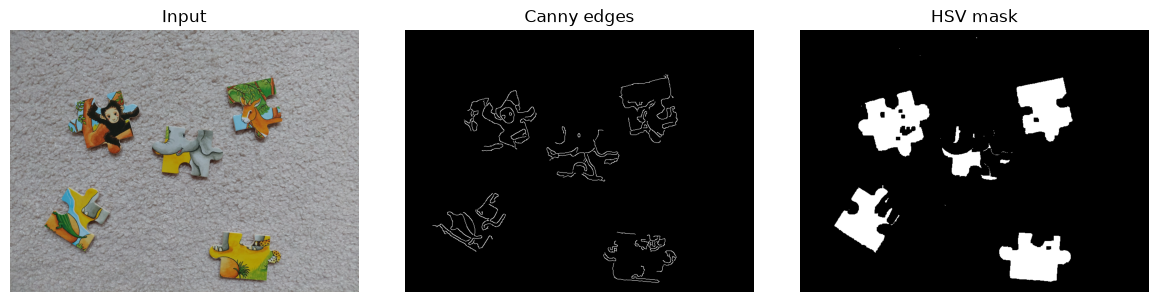

In [232]:
def load_photo(filename):
    image = cv.imread(filename)
    if image is None:
        raise FileNotFoundError(filename)
    scale = min(1.0, 800 / max(image.shape[:2]))
    return cv.resize(image, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)


def show_images(items, rows, cols):
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))
    for ax, (title, image) in zip(axes.flat, items):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


img = load_photo("jigsaw1.jpg")
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
edges = cv.Canny(cv.GaussianBlur(gray, (9, 9), 2), 30, 100, L2gradient=True)

saturation = cv.cvtColor(img, cv.COLOR_BGR2HSV)[:, :, 1]
_, mask = cv.threshold(saturation, 55, 255, cv.THRESH_BINARY)
mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, np.ones((7, 7), np.uint8))

rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
show_images([("Input", rgb), ("Canny edges", edges), ("HSV mask", mask)], 1, 3)

### Separating the pieces from the background

In [233]:
def ellipse(size):
    return cv.getStructuringElement(cv.MORPH_ELLIPSE, (size, size))


def contours_of(mask):
    contours, _ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    return contours


def color_seeds(lab, chroma, texture):
    threshold, strong = cv.threshold(chroma, 0, 255, cv.THRESH_BINARY | cv.THRESH_OTSU)
    weak = np.uint8(chroma > 0.42 * threshold)
    weak = cv.morphologyEx(weak, cv.MORPH_OPEN, ellipse(5))
    lightness, a, b = cv.split(lab)

    labels = np.zeros_like(chroma)
    labels[cv.dilate(weak, ellipse(65)) > 0] = cv.GC_PR_BGD
    labels[cv.dilate(weak, ellipse(21)) > 0] = cv.GC_PR_FGD
    labels[cv.morphologyEx(strong, cv.MORPH_OPEN, ellipse(5)) > 0] = cv.GC_FGD

    # Mark textured glare as background and smooth areas near a color seed as foreground.
    glare = cv.dilate(np.uint8(lightness > 200), ellipse(19)) > 0
    labels[(chroma < 8) & glare & (texture > 12)] = cv.GC_BGD
    near_color = cv.dilate(weak, ellipse(33)) > 0
    labels[near_color & (texture < 1.8) & (chroma > np.median(chroma) + 2)] = cv.GC_FGD

    surface = np.clip(6 * texture + 0.25 * lightness, 0, 255).astype(np.uint8)
    return cv.merge((surface, a, b)), labels


def board_seeds(residual):
    roughness = np.clip(12 * cv.blur(residual, (17, 17)), 0, 255).astype(np.uint8)
    _, smooth = cv.threshold(roughness, 0, 255, cv.THRESH_BINARY_INV | cv.THRESH_OTSU)
    contours = contours_of(cv.morphologyEx(smooth, cv.MORPH_OPEN, ellipse(15)))
    if not contours:
        return None
    hull = cv.convexHull(max(contours, key=cv.contourArea))
    labels = np.full_like(smooth, cv.GC_PR_BGD)
    cv.drawContours(labels, [hull], -1, cv.GC_PR_FGD, cv.FILLED)
    return labels

### Finding seams

On an assembled board, several pieces share one outer contour. Many seams have a straight section followed by a curved tab. The code starts at horizontal and vertical lines and follows nearby curves. This works best when the board is roughly aligned with the photo.

In [234]:
def ridge_strength(gray, operation):
    lines = cv.morphologyEx(gray, operation, ellipse(5))
    return lines / (1 + cv.GaussianBlur(lines, (0, 0), 5))


def find_seams(gray, region, low_color):
    gray = cv.GaussianBlur(gray.astype(np.float32), (3, 3), 0.65)
    score = ridge_strength(gray, cv.MORPH_BLACKHAT)
    if low_color:
        score = np.maximum(score, 0.65 * ridge_strength(gray, cv.MORPH_TOPHAT))
        threshold, length, steps = 1.0, 9, 16
    else:
        threshold, length, steps = 1.35, 19, 5
    candidates = np.uint8(score > threshold) * cv.erode(region, ellipse(5))

    # Start with straight sections. Extend them only along visible lines.
    kernel = np.ones((1, length), np.uint8)
    horizontal = cv.morphologyEx(candidates, cv.MORPH_OPEN, kernel)
    vertical = cv.morphologyEx(candidates, cv.MORPH_OPEN, kernel.T)
    seams = horizontal | vertical
    for _ in range(steps):
        seams = cv.dilate(seams, None) & candidates
    return seams

In [235]:
def segment_puzzle(photo):
    gray = cv.cvtColor(photo, cv.COLOR_BGR2GRAY)
    lab = cv.cvtColor(photo, cv.COLOR_BGR2LAB)
    _, a, b = cv.split(lab.astype(np.float32))
    chroma = np.hypot(a - 128, b - 128).astype(np.uint8)
    residual = cv.absdiff(gray, cv.GaussianBlur(gray, (0, 0), 2)).astype(np.float32)
    low_color = np.percentile(chroma, 99) < 12

    if low_color:
        features, labels = photo, board_seeds(residual)
        if labels is None:
            return np.zeros_like(gray)
    else:
        features, labels = color_seeds(lab, chroma, cv.blur(residual, (9, 9)))

    cv.setRNGSeed(0)
    cv.grabCut(features, labels, None, None, None, 4, cv.GC_INIT_WITH_MASK)
    mask = (labels % 2) * 255  # GrabCut foreground labels are 1 and 3.
    if low_color:
        pieces = sorted(contours_of(mask), key=cv.contourArea, reverse=True)[:1]
    else:
        mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, ellipse(5))
        pieces = [c for c in contours_of(mask) if cv.contourArea(c) > 0.0025 * mask.size]

    outlines = cv.drawContours(np.zeros_like(gray), pieces, -1, 255, 2)
    joined = [c for c in pieces if cv.contourArea(c) > 0.08 * mask.size]
    if joined:
        region = cv.drawContours(np.zeros_like(gray), joined, -1, 255, cv.FILLED)
        outlines |= find_seams(gray, region, low_color)
    return outlines

### Results on all six photos

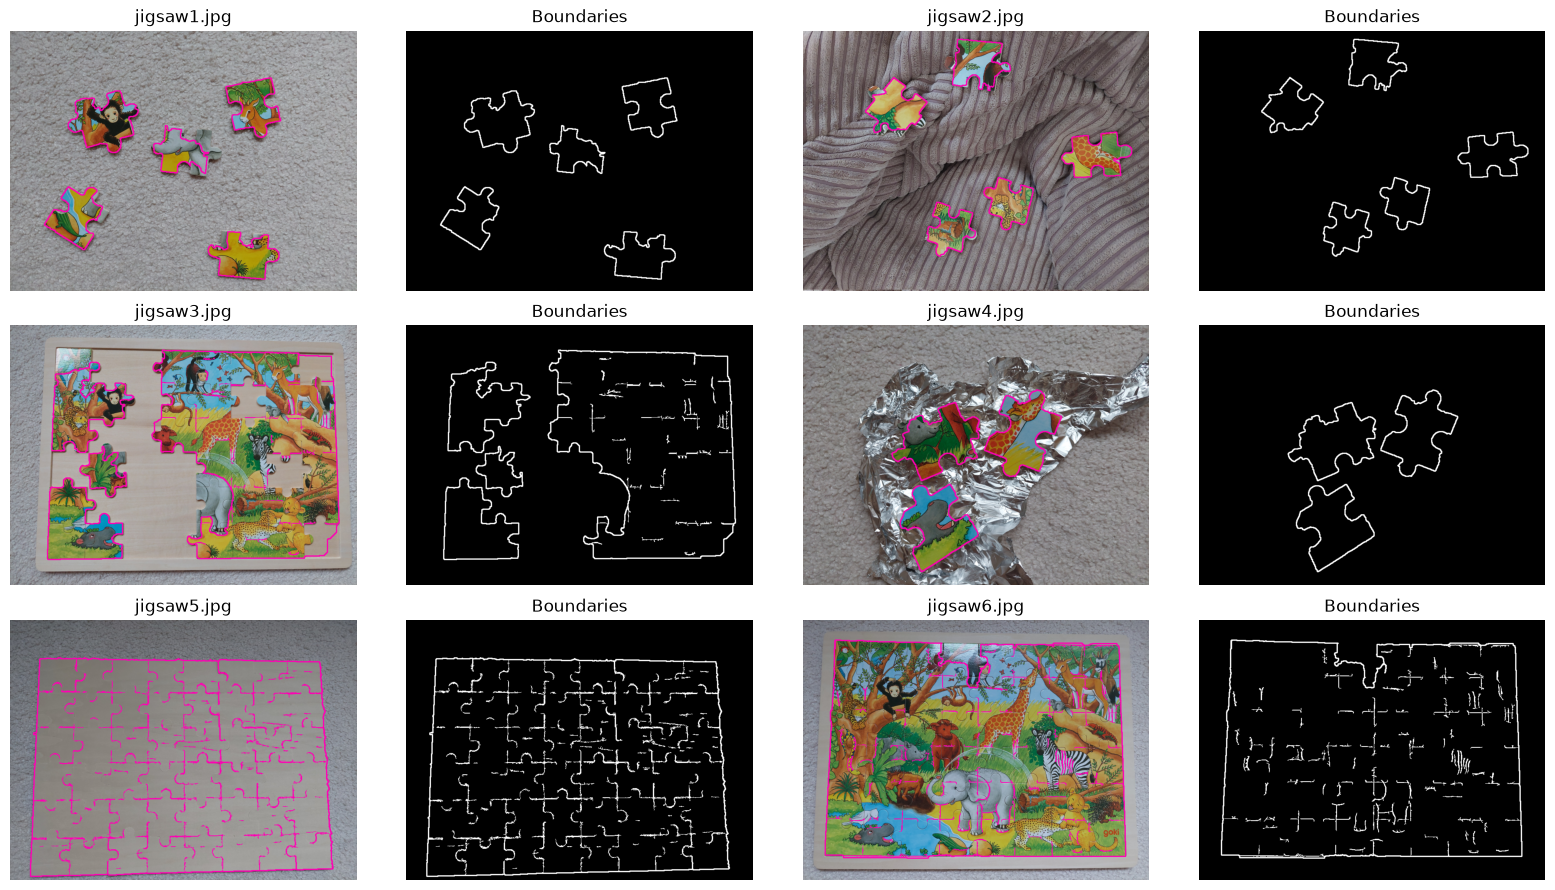

In [236]:
results = []
for i in range(1, 7):
    filename = f"jigsaw{i}.jpg"
    photo = load_photo(filename)
    outlines = segment_puzzle(photo)
    overlay = cv.cvtColor(photo, cv.COLOR_BGR2RGB)
    overlay[outlines > 0] = (255, 0, 180)
    results.extend([(filename, overlay), ("Boundaries", outlines)])

show_images(results, 3, 4)